# 01 - Explore data
Goal: understand the burglary data and the neighbourhood data before building the dataset

In [1]:
import pandas as pd # work with tables (DataFrames)
import matplotlib.pyplot as plt # make charts


In [11]:
# Load the raw burglary data saved in notebook 00 (pandas unzip the .gz file automatically)
burglary = pd.read_csv("../data/raw/47022NED_burglary_monthly_buurt.csv.gz")
print(burglary.shape) # show the number of rows and columns, should be (2607210,5)
burglary.head() # show the first 5 rows of the table

(2607210, 5)


,ID,SoortMisdrijf,WijkenEnBuurten,Perioden,GeregistreerdeMisdrijven_1
0,3274677,1.1.1,BU16800000,2012MM01,1
1,3274678,1.1.1,BU16800000,2012MM02,3
2,3274679,1.1.1,BU16800000,2012MM03,0
3,3274680,1.1.1,BU16800000,2012MM04,1
4,3274681,1.1.1,BU16800000,2012MM05,0


In [12]:
# 'Perioden' looks like '2012MM01': the first 4 characters are the year, the last 2 are the month
burglary["year"] = burglary["Perioden"].str[:4].astype(int)     # '2012MM01' -> 2012
burglary["month"] = burglary["Perioden"].str[-2:].astype(int)   # '2012MM01' -> 1

# Give the long Dutch column names short English names
burglary = burglary.rename(columns={"WijkenEnBuurten": "buurt_code",
                                    "GeregistreerdeMisdrijven_1": "burglaries"})
burglary.head()

,ID,SoortMisdrijf,buurt_code,Perioden,burglaries,year,month
0,3274677,1.1.1,BU16800000,2012MM01,1,2012,1
1,3274678,1.1.1,BU16800000,2012MM02,3,2012,2
2,3274679,1.1.1,BU16800000,2012MM03,0,2012,3
3,3274680,1.1.1,BU16800000,2012MM04,1,2012,4
4,3274681,1.1.1,BU16800000,2012MM05,0,2012,5


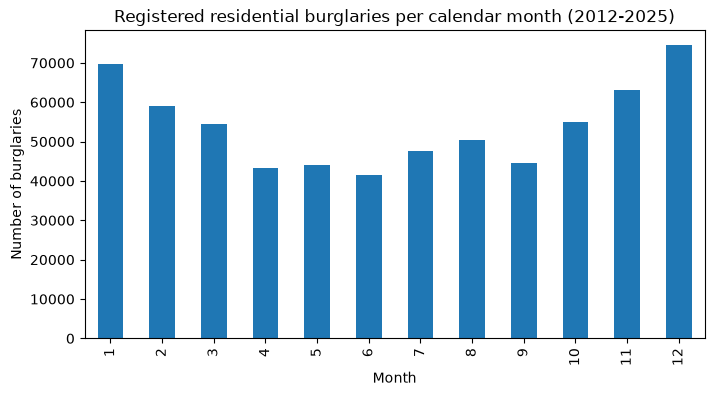

In [13]:
# Use only complete years (2026 only has January-September, which would make Oct-Dec look too low)
complete_years = burglary[burglary["year"] <= 2025]

# Total burglaries per calendar month, all years and neighbourhoods combined
per_month = complete_years.groupby("month")["burglaries"].sum()

per_month.plot(kind="bar", figsize=(8, 4))
plt.title("Registered residential burglaries per calendar month (2012-2025)")
plt.xlabel("Month")
plt.ylabel("Number of burglaries")
plt.show()

**Finding:** 
Burglaries peak in the dark months (Dec ≈ 74k, Jan ≈ 70k) and are lowest in early summer (Jun ≈ 41k). 
The dark season (Oct–Mar) accounts for roughly 58% of all burglaries. 
This supports our use case: prevention planned on 1 October for the Oct–Mar season.